# Automobile Data Analysis – Exploratory Data Analysis #

## Objectives ##

* Understand automobile features.
* Analyze car prices and brands.
* Compare fuel types.
* Study engine size and horsepower.
* Analyze mileage and car body styles.
* Identify useful patterns using visualizations.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [3]:
df = pd.read_csv(r"C:\Users\Dell\Downloads\Automobile_data.csv")
print("Data Loaded Successfully!")

Data Loaded Successfully!


In [4]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


In [5]:
df.tail()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.4,23.0,106,4800,26,27,22470
204,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625


In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 205
Number of Columns: 26
Dataset Shape: (205, 26)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

In [10]:
for column in df.columns:
    print(column)

symboling
normalized-losses
make
fuel-type
aspiration
num-of-doors
body-style
drive-wheels
engine-location
wheel-base
length
width
height
curb-weight
engine-type
num-of-cylinders
engine-size
fuel-system
bore
stroke
compression-ratio
horsepower
peak-rpm
city-mpg
highway-mpg
price


In [11]:
df.describe()

,symboling,wheel-base,length,width,height,curb-weight,engine-size,compression-ratio,city-mpg,highway-mpg
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,10.142537,25.219512,30.751220
std,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,3.972040,6.542142,6.886443
min,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,7.000000,13.000000,16.000000
25%,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,8.600000,19.000000,25.000000
50%,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,9.000000,24.000000,30.000000
75%,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,9.400000,30.000000,34.000000
max,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,23.000000,49.000000,54.000000


In [12]:
missing_symbols = (df == "?").sum()

print("Missing Values Represented by '?'")
print(missing_symbols[missing_symbols > 0])

Missing Values Represented by '?'
normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64


In [13]:
df = df.replace("?", np.nan)

print("Missing symbols replaced successfully!")

Missing symbols replaced successfully!


In [14]:
numeric_columns = [
    "normalized-losses",
    "bore",
    "stroke",
    "horsepower",
    "peak-rpm",
    "price"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_columns].dtypes)

normalized-losses    float64
bore                 float64
stroke               float64
horsepower           float64
peak-rpm             float64
price                float64
dtype: object


In [15]:
print(df.isnull().sum())

symboling             0
normalized-losses    41
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 4
dtype: int64


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage[missing_percentage > 0])


normalized-losses    20.00000
num-of-doors          0.97561
bore                  1.95122
stroke                1.95122
horsepower            0.97561
peak-rpm              0.97561
price                 1.95122
dtype: float64


In [17]:
clean_df = df.dropna(subset=["price"]).copy()

print("Original Rows:", len(df))
print("Rows After Removing Missing Prices:", len(clean_df))


Original Rows: 205
Rows After Removing Missing Prices: 201


In [18]:
numeric_features = [
    "normalized-losses",
    "bore",
    "stroke",
    "horsepower",
    "peak-rpm"
]

for col in numeric_features:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

print(clean_df[numeric_features].isnull().sum())


normalized-losses    0
bore                 0
stroke               0
horsepower           0
peak-rpm             0
dtype: int64


In [19]:
clean_df["num-of-doors"] = clean_df["num-of-doors"].fillna(
    clean_df["num-of-doors"].mode()[0]
)

print(clean_df["num-of-doors"].value_counts())


num-of-doors
four    115
two      86
Name: count, dtype: int64


In [20]:
print("Total Missing Values:", clean_df.isnull().sum().sum())


Total Missing Values: 0


In [21]:
print("Duplicate Records:", clean_df.duplicated().sum())


Duplicate Records: 0


In [22]:
print("Cleaned Dataset Shape:", clean_df.shape)

clean_df.info()


Cleaned Dataset Shape: (201, 26)
<class 'pandas.core.frame.DataFrame'>
Index: 201 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    float64
 2   make               201 non-null    object 
 3   fuel-type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num-of-doors       201 non-null    object 
 6   body-style         201 non-null    object 
 7   drive-wheels       201 non-null    object 
 8   engine-location    201 non-null    object 
 9   wheel-base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb-weight        201 non-null    int64  
 14  engine-type        201 non-null    object 
 15  num-of-cylinders   201 non-null    object 
 16

In [23]:
brand_count = clean_df["make"].value_counts()

print(brand_count)


make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
volkswagen       12
subaru           12
peugot           11
volvo            11
dodge             9
mercedes-benz     8
bmw               8
plymouth          7
audi              6
saab              6
porsche           4
jaguar            3
chevrolet         3
alfa-romero       3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64


In [24]:
brand_prices = clean_df.groupby("make")["price"].mean()

print(brand_prices.sort_values(ascending=False))


make
jaguar           34600.000000
mercedes-benz    33647.000000
porsche          31400.500000
bmw              26118.750000
volvo            18063.181818
audi             17859.166667
mercury          16503.000000
alfa-romero      15498.333333
peugot           15489.090909
saab             15223.333333
mazda            10652.882353
nissan           10415.666667
volkswagen       10077.500000
toyota            9885.812500
renault           9595.000000
mitsubishi        9239.769231
isuzu             8916.500000
subaru            8541.250000
honda             8184.692308
plymouth          7963.428571
dodge             7875.444444
chevrolet         6007.000000
Name: price, dtype: float64


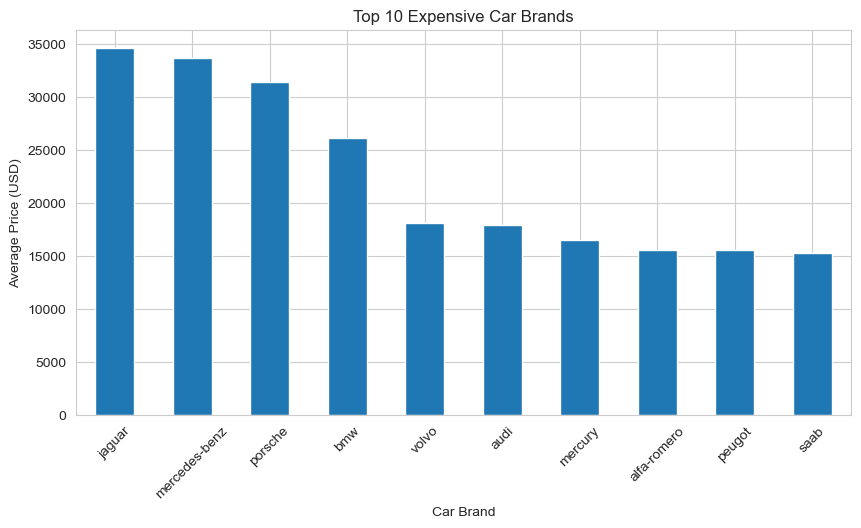

In [25]:
top_brands = brand_prices.sort_values(ascending=False).head(10)

top_brands.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Expensive Car Brands")
plt.xlabel("Car Brand")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=45)
plt.show()


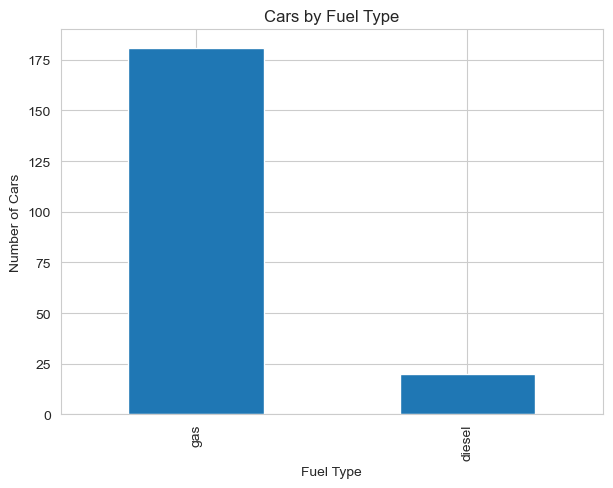

In [26]:
fuel_count = clean_df["fuel-type"].value_counts()

fuel_count.plot(kind="bar", figsize=(7, 5))

plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.show()


In [27]:
fuel_prices = clean_df.groupby("fuel-type")["price"].mean()

print(fuel_prices)


fuel-type
diesel    15838.15000
gas       12916.40884
Name: price, dtype: float64


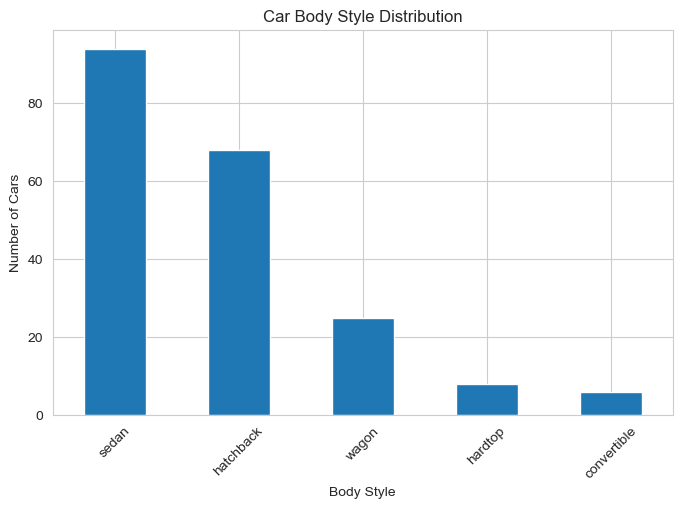

In [28]:
body_count = clean_df["body-style"].value_counts()

body_count.plot(kind="bar", figsize=(8, 5))

plt.title("Car Body Style Distribution")
plt.xlabel("Body Style")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()


In [29]:
body_prices = clean_df.groupby("body-style")["price"].mean()

print(body_prices.sort_values(ascending=False))


body-style
hardtop        22208.500000
convertible    21890.500000
sedan          14459.755319
wagon          12371.960000
hatchback       9957.441176
Name: price, dtype: float64


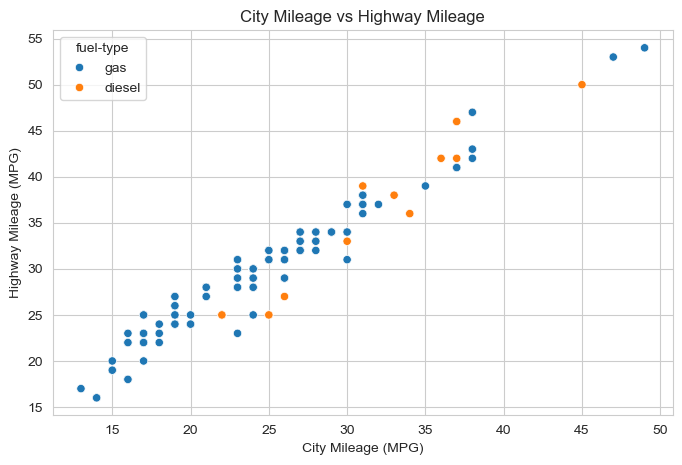

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="city-mpg",
    y="highway-mpg",
    hue="fuel-type"
)

plt.title("City Mileage vs Highway Mileage")
plt.xlabel("City Mileage (MPG)")
plt.ylabel("Highway Mileage (MPG)")
plt.show()


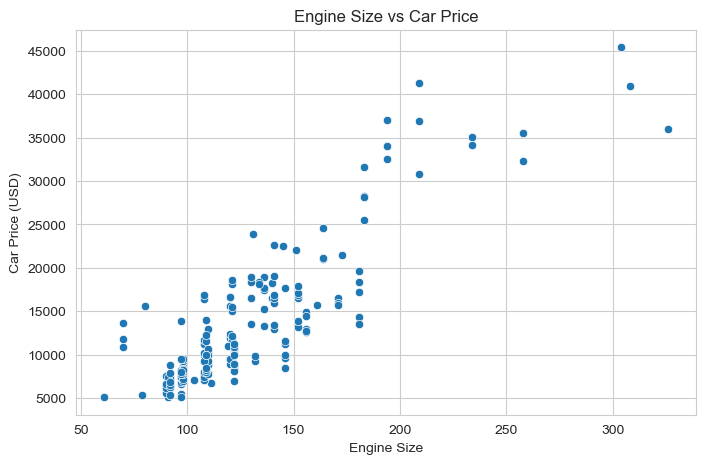

In [31]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="engine-size",
    y="price"
)

plt.title("Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Car Price (USD)")
plt.show()


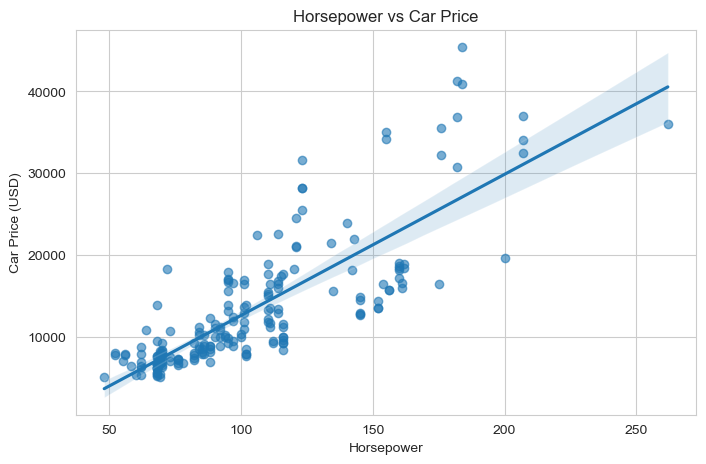

In [32]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=clean_df,
    x="horsepower",
    y="price",
    scatter_kws={"alpha": 0.6}
)

plt.title("Horsepower vs Car Price")
plt.xlabel("Horsepower")
plt.ylabel("Car Price (USD)")
plt.show()


# AUTOMOBILE DATA ANALYSIS – EDA REPORT #

## 1. Introduction

The Automobile Data Analysis project focuses on understanding different automobile features and their relationship with car prices.

Exploratory Data Analysis (EDA) is performed using Python to identify patterns in car brands, fuel types, body styles, mileage, engine size, and horsepower.

## 2. Objectives ##

Understand the automobile dataset.
Analyze different car brands.
Compare car prices.
Study petrol and diesel vehicles.
Analyze car body styles.
Understand mileage performance.
Explore the relationship between engine size and price.
Study horsepower and car price relationships.

## 3. Dataset Description ##

Dataset Name: Automobile Dataset

Original records: 205
Number of columns: 26
Records after cleaning: 201

## Important Features ##

Feature	Description
make	Car manufacturer
fuel-type	Fuel used by the car
body-style	Type of car body
num-of-doors	Number of doors
engine-size	Engine size
horsepower	Engine power
city-mpg	City mileage
highway-mpg	Highway mileage
price	Car price

## 4. Data Cleaning and Preprocessing ##

The following steps were performed:

Loaded the dataset using Pandas.
Checked rows, columns, and data types.
Replaced ? symbols with missing values.
Converted numerical columns into numeric data types.
Identified missing values.
Removed records with missing car prices.
Filled missing numerical values using the median.
Filled missing door values using the mode.
Checked duplicate records.
Verified the cleaned dataset.
    
Final cleaned dataset: 201 rows and 26 columns.

Remaining missing values: 0

Duplicate records: 0

## 5. Exploratory Data Analysis

## A. Car Brand Analysis

Analyzed the number of cars available under each manufacturer and compared their average prices.

## B. Fuel Type Analysis

Compared petrol and diesel vehicles based on their number and average prices.

## C. Body Style Analysis

Studied different body styles, including sedan, hatchback, wagon, hardtop, and convertible.

## D. Mileage Analysis

Compared city mileage and highway mileage using scatter plots.

## E. Engine Size Analysis

Used scatter plots to understand the relationship between engine size and car price.

## F. Horsepower Analysis

Used regression visualization to study the relationship between horsepower and car price.

## 6. Key Findings

Based on the actual dataset:

Total original records: 205
Records after cleaning: 201
Total car manufacturers: 22
Most frequently appearing brand: Toyota (32 cars)
Average car price: 13,207.13
Minimum car price: 5,118
Maximum car price: 45,400
Most common fuel type: Gas (181 cars)
Most common body style: Sedan (94 cars)
Highest average-price brand: Jaguar (34,600)
Average city mileage: 25.18 MPG
Average highway mileage: 30.69 MPG
Note: The dataset does not explicitly specify the currency unit for the price column.

## 7. Important Observations

Toyota has the highest number of records in the dataset.
Gas vehicles are more common than diesel vehicles.
Sedan is the most frequently occurring body style.
Jaguar has the highest average price among the brands in this dataset.
Diesel cars have a higher average price than gas cars in this dataset.
Engine size and car price show a strong positive correlation.
Horsepower and car price also show a strong positive correlation.
Highway mileage is higher on average than city mileage.

## 8. Conclusion

The Automobile EDA project helped us understand different automobile features and their relationship with car prices.

Data cleaning, statistical analysis, and visualization were used to explore car manufacturers, fuel types, body styles, mileage, engine size, and horsepower.

The analysis showed that automobile prices are associated with features such as engine size and horsepower. It also helped identify popular car brands and common vehicle types.

Overall, this project provided practical experience in using Python for real-world automobile data analysis.

## 9. Tools and Technologies Used

Python
Jupyter Notebook
Pandas
NumPy
Matplotlib
Seaborn
Project Status: Automobile Exploratory Data Analysis – Completed.